![AES 770 Masthead](https://kyrill.ias.sdsmt.edu/wjc/eduresources/AES_744_Masthead.png)

# Cracking and Displaying Voronoi Polygons in MPAS (1-D & n-D Data )

## Objective

This script is an example of cracking a given MPAS file that's been initialized for surface conditions (terrain, land cover, soils, etc).

Specifically, it addresses the use of Voronoi polygons, which are the defining feature of MPAS, enabling it to present great detail in one area while maintaining global modeling economy by reducing detail on the "far side" of your area of interest.  

Being able to present the polygons as-is may be desirable from a "sci-art" perspective, but more importantly, it may be valuable when providing a discretized image of certain variables, especially those associated with the land surface (vegetation type, terrain, etc.).

When plotting continuous data, some of the existing available support scripts for plotting MPAS output will be preferable. 

## Libraries

For this exercise, you will need the following library.


* [numpy](https://numpy.org/): Python's "go-to" library for math and array/matrix structures
* [pandas](https://pandas.pydata.org/): A fast, powerful, flexible and easy to use open source data analysis and manipulation tool that has structures similar to R's "DataFrame"
* [matplotlib](https://matplotlib.org/stable/): Python's "go-to" Graphics Library.

* [xarray](https://docs.xarray.dev/en/stable/): Python's multi-dimensional array library designed to work well with netCDF and other self-describing files. 

*  [CartoPy](https://cartopy.readthedocs.io/stable/): A map projection library. We are specifically requesting the following sub-libraries
    *  [CartoPy.crs](https://cartopy.readthedocs.io/stable/reference/crs.html): Cartopy's Coordinate Reference System (CRS) operators. This is the information needed to draw the various projections.
    *  [CartoPy.feature](https://cartopy.readthedocs.io/stable/matplotlib/feature_interface.html): Cartopy's Feature Plotting Interface
      
* [geopandas](https://geopandas.org/en/stable/index.html): provides geospatial geometry support (e.g., polygons, points, etc.) for use with Pandas.

* [shapely](https://shapely.readthedocs.io/en/stable/): An underlying geometry library for mapping geospatial data that you will often want to have ready if you are working with geopandas or cartopy.  Here, this will be used to create our polygons

* [calendar](https://docs.python.org/3/library/calendar.html): I'm using the calendar base python library below as well


In [1]:
##################################################
#
# Libraries
#

import numpy              as np
import pandas             as pd

import matplotlib         as mpl
import matplotlib.pyplot  as plt

import xarray             as xr

import cartopy            as cartopy
import cartopy.crs        as ccrs
import cartopy.feature    as cfeature

import geopandas          as gpd

import shapely            as shapely
import shapely.geometry   as geom

from   shapely.validation import make_valid

import calendar           as calendar

#
##################################################

## Thematic Color Table for this Example

For visualization purposes land cover will be a good easy reference to display the Voroni polygons from MPAS.

I have a makeshift colortable for the MODIS 20 Categories for Land Use/Land Cover (LULC) which is representeded in MPAS as the variable "ivtype" (integer vegetation type).

I'm using a simple CSV comma-delimited file to hold the colors, category code, and category text name.

,ivgtyp,Color,Land Cover
0,0,#000000,Undefined
1,1,#248926,Evergreen Needleleaf Forest
2,2,#33D239,Evergreen Broadleaf Forest
3,3,#9DCC33,Deciduous Needleleaf Forest
4,4,#9CF89A,Deciduous Broadleaf Forest
5,5,#91BA8D,Mixed Forests
6,6,#B9908C,Closed Shrublands
7,7,#F4DFB2,Open Shrublands
8,8,#DBEBA0,Woody Savannas
9,9,#F5D90C,Savannas


IVGTYP Color Table


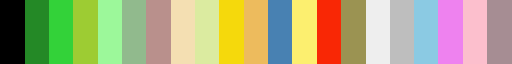

In [15]:
##################################################
#
# Thematic Color Table 
#

color_table_csv = "https://thredds.ias.sdsmt.edu:8443/thredds/fileServer/CLASS_Examples/Modis_20_category_Color_Table.csv"

df_color_modis = pd.read_csv(filepath_or_buffer = color_table_csv,
                             index_col          =           False)

display(df_color_modis)

# Extract Land Cover Descriptions and Colors

land_cover_list   = list(df_color_modis["Land Cover"].values)
land_cover_colors = list(df_color_modis["Color"].values)

# Create some simple color palettes (nothing too complex
modis_color_palette = dict(zip(  land_cover_list,
                               land_cover_colors))

ivgtyp_color_palette = dict(zip(              range(21),
                                df_color_modis["Color"])) 

# Create and Display Color Table as a Demo Bar
ivgtyp_color_table = mpl.colors.ListedColormap(df_color_modis["Color"])

print("IVGTYP Color Table")
ivgtyp_color_table

#
##################################################

# Crack your Static Fields Initialization from MPAS

For this, we only need the static initialization from MPAS (atmosphere_initial) output since this is a demo (or a presentation quality image for pubs or talks)

Here we only need the traditional [xarray.open_dataset()](https://docs.xarray.dev/en/stable/generated/xarray.open_dataset.html) read.  And for the general file, I'm just using one of the example grids from one of the MPAS Tutorials.

We will want to display this information as a reference for extracting our polygons and for choosing which fields to display in this demo.

<div class="alert alert-warning" role="alert">
  <b>Warning:</b> the MPAS "init" files may be written in a netCDF data "kind" that doesn't work well with THREDDS data services.  For the example below, I am using a copy that I converted from its original "64-bit data" or "cdf5" format into a "64-bit offset" data kind file.</p>
    <p>Also, if you access the file below from our THREDDS server, accessing the polygons will be VERY slow.  You may be better off downloading it and using it locally, or just using your own.</p>
</div>


In [3]:
##################################################
#
# Access your Input NetCDF File
#

initialization_file = "https://thredds.ias.sdsmt.edu:8443/thredds/dodsC/CLASS_Examples/x1.10242.init.64offset.nc"

ds_init = xr.open_dataset(filename_or_obj = initialization_file)

ds_init

#
##################################################

<xarray.Dataset> Size: 19MB
Dimensions:                   (Time: 1, nCells: 10242, nEdges: 30720,
                               nVertices: 20480, TWO: 2, maxEdges: 10,
                               maxEdges2: 20, vertexDegree: 3, R3: 3,
                               nMonths: 12, nSoilComps: 8, FIFTEEN: 15)
Coordinates:
  * Time                      (Time) datetime64[ns] 8B 2010-10-23
Dimensions without coordinates: nCells, nEdges, nVertices, TWO, maxEdges,
                                maxEdges2, vertexDegree, R3, nMonths,
                                nSoilComps, FIFTEEN
Data variables: (12/78)
    xtime                     (Time) |S64 64B ...
    latCell                   (nCells) float32 41kB ...
    lonCell                   (nCells) float32 41kB ...
    xCell                     (nCells) float32 41kB ...
    yCell                     (nCells) float32 41kB ...
    zCell                     (nCells) float32 41kB ...
    ...                        ...
    ol3                       (nCells) float32 41kB ...
    ol4                       (nCells) float32 41kB ...
    deriv_two                 (nEdges, TWO, FIFTEEN) float32 4MB ...
    cell_gradient_coef_x      (nCells, maxEdges) float32 410kB ...
    cell_gradient_coef_y      (nCells, maxEdges) float32 410kB ...
    coeffs_reconstruct        (nCells, maxEdges, R3) float32 1MB ...
Attributes: (12/73)
    model_name:                       mpas
    core_name:                        init_atmosphere
    version:                          8.4.0
    source:                           MPAS
    Conventions:                      MPAS
    git_version:                      unknown
    ...                               ...
    config_explicit_proc_decomp:      NO
    config_proc_decomp_file_prefix:   graph.info.part.
    file_id:                          nma2pumkr7
    DODS.strlen:                      64
    DODS.dimName:                     StrLen
    DODS_EXTRA.Unlimited_Dimension:   Time

## Make a master DataFrame for your Polygons

Here, we are going to loop through all of our available cells, extract the defining Voronoi polygons and the central latitude and longitude (also the terrain elevation), and then map them.  

The goal here is to store the spatial information into a [geopandas.GeoDataFrame()](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html) to which we can later join with specific fields from your MPAS output or initialization files.

All information should be "joinable" using the "nCell" attribute using the dimension coordinate "nCells" from the MPAS netCDF files.

Since there is a lot going on inside the loop, I am documenting most of the steps in the code below.


<div class="alert alert-danger" role="alert">
  <b>Another (and more earnest) Warning:</b> If you are rotating one of the rotated "variable resolution" meshes, and you want to map it later using a global perspective where the "edge of the world" is at 180° E/W, then you will want to also set any longitude that's over 180 degrees east to negative values.  You can see that patch in the code below.
</div>

In [4]:
##################################################
# 
# Generate a GeoDataFrame of our Vorini Polygons
#

# Start with an empty list in which to put your polygons

polygons  = []

# Initiate a loop through all "Cells" - Cells are numbered
#   monotonically so you can also archive the centroid lat 
#   and centroid lon.

for i in range(ds_init.sizes["nCells"]):
    ##########################################
    # 

    # For each Cell, extract the verticies.  Active verticies
    #   have indices that are over 1, but in Python, all indices
    #   have are expected to start at zero, so we'll shave off 
    #   the first index and toss the ones that are zero or higher
    #   as the missing vertex placeholders are -1 
    
    vertices = ds_init["verticesOnCell"][i, :].values - 1 
    vertices = vertices[vertices >= 0]
    
    # Now extract the latitude (latVertex) and longitude (lonVertex)
    #    and convert from the native units of radians into
    #    degrees east and degrees north.
    
    lons_verticies = ds_init["lonVertex"][vertices].values * 180 / np.pi
    lats_verticies = ds_init["latVertex"][vertices].values * 180 / np.pi

    # This patch becomes active when you are working with longitudes
    #   that go from 0 to 360 degrees east.  That's great if you are working
    #   over the Pacific, but it may cause problems in other applications.

    lons_verticies = (lons_verticies + 180) % 360 - 180

    # "ZIP" the lat/lon pairs into 2xn tupples and then 
    #     colate them into a shapely polygon (these will then
    #     go into a geopandas.GeoDataFrame.  And finally, append
    #     to the list you made.
    
    polygons.append(geom.Polygon(zip(lons_verticies, 
                                     lats_verticies)))

    #
    ##########################################

# You can also extract the centroid information
#    If you are like me and consider terrain a 
#    height coordinate, you can do that here too.

lons_centroid = ds_init["lonCell"].values * 180 / np.pi
lats_centroid = ds_init["latCell"].values * 180 / np.pi
z_centroid    = ds_init["ter"].values

# Create Base GeoDataFrame
#   You can then "index" the GeoDataFrame with the Cells coordinate 
#       so you can later associate properties of each polygon to
#       a geopandas.GeoDataFrame column 

gdf_voronoi = gpd.GeoDataFrame(data    = {"longitude": lons_centroid,
                                           "latitude": lats_centroid,
                                          "elevation":    z_centroid},
                              geometry = polygons, 
                              crs      = "EPSG:4326")

# For a pandas or geopandas Dataframe, we can name the index by nCells or Cells
#   I prefer the latter.  This index will be used to line up your MPAS output
#   fields to these mapable polygons or centroid lat/lon pairs.

gdf_voronoi.index.name = "Cell"

# Display the GeoDataFrame

gdf_voronoi

#
##################################################

,longitude,latitude,elevation,geometry
Cell,,,,
0,185.047043,26.565050,0.000000,"POLYGON ((-176.13182 26.21656, -174.95293 25.4..."
1,257.047058,26.565050,1219.221558,"POLYGON ((-103.68957 27.46281, -104.13183 26.2..."
2,117.454483,90.000000,0.000000,"POLYGON ((-66.95294 88.88795, 5.04706 88.88795..."
3,5.047055,-26.565050,0.000000,"POLYGON ((4.31042 -27.46281, 5.78368 -27.46281..."
4,77.047050,-26.565050,0.000000,"POLYGON ((75.86816 -26.21656, 76.31042 -27.462..."
...,...,...,...,...
10237,255.211731,-53.242661,0.000000,"POLYGON ((-102.95294 -53.87894, -102.95294 -52..."
10238,257.047058,-51.354534,0.000000,"POLYGON ((-101.22746 -50.69868, -102.95294 -50..."
10239,185.047043,-51.354534,0.000000,"POLYGON ((-173.22746 -50.69868, -174.95293 -50..."


## Merging Quantity Data Into your Voronoi GeoDataFrame (1-Dimensional Index Joining Example)

For single "one-off" cases, you could probably follow the steps above using the code block.

But since for some of us a single model domain multiple times, we may want to save the above and then just crack it open for later use, for example, "today's forecast."

So here I'm going to extract some select variables and manipulate them accordingly in a working [pandas.DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) and then "join" on the "Cells" index to the Voronoi spatial dataframe from above.

### Plain 1-Dimensional Joining

I'll start here with the seasonally-independent land cover & mask.

The outline steps here will be to 

* Convert the xarray.DataArrays into pandas.DataFrames with the Cells as the Index using [xarray.Dataset.to_dataframe()](https://docs.xarray.dev/en/latest/generated/xarray.Dataset.to_dataframe.html)
* Renaming my index because I want them to be called "Cell."
* Join the Voronoi spatial data to it with [pandas.DataFrame.merge()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.merge.html)

Also, here is an example of making categorical data in a Pandas Dataframe.  If you are familiar with "R" this is the equivalent of a ["factor" in R](https://r4ds.had.co.nz/factors.html).  This is done using [pandas.Categorical()](https://pandas.pydata.org/docs/reference/api/pandas.Categorical.html)
In this example, I am going to just extract the vegetation & landmask data. 

In [5]:
##################################################
# 
# Extract MPAS Fields to Spatial Data Array (1-D example)
#

# Pull only Selected Information from Xarray to it's own DataFrame

df_data            = ds_init[["landmask", 
                                "ivgtyp"]].to_dataframe()
# rename the index

df_data.index.name = "Cell"

# It just might be nice to have a "people-friendly" label for the land cover type

df_data["Land Cover"] = np.array(land_cover_list)[df_data["ivgtyp"].values]

df_data['Land Cover'] = pd.Categorical(values     = df_data['Land Cover'], 
                                       categories = land_cover_list, 
                                       ordered    = True)

# Merge DataFrame onto the Voronoi GeoDataFrame

gdf_land = gdf_voronoi.merge(right       = df_data, 
                            left_index  =    True, 
                            right_index =    True)

gdf_land

#
##################################################

,longitude,latitude,elevation,geometry,landmask,ivgtyp,Land Cover
Cell,,,,,,,
0,185.047043,26.565050,0.000000,"POLYGON ((-176.13182 26.21656, -174.95293 25.4...",0,17,Water
1,257.047058,26.565050,1219.221558,"POLYGON ((-103.68957 27.46281, -104.13183 26.2...",1,7,Open Shrublands
2,117.454483,90.000000,0.000000,"POLYGON ((-66.95294 88.88795, 5.04706 88.88795...",0,17,Water
3,5.047055,-26.565050,0.000000,"POLYGON ((4.31042 -27.46281, 5.78368 -27.46281...",0,17,Water
4,77.047050,-26.565050,0.000000,"POLYGON ((75.86816 -26.21656, 76.31042 -27.462...",0,17,Water
...,...,...,...,...,...,...,...
10237,255.211731,-53.242661,0.000000,"POLYGON ((-102.95294 -53.87894, -102.95294 -52...",0,17,Water
10238,257.047058,-51.354534,0.000000,"POLYGON ((-101.22746 -50.69868, -102.95294 -50...",0,17,Water
10239,185.047043,-51.354534,0.000000,"POLYGON ((-173.22746 -50.69868, -174.95293 -50...",0,17,Water


### Multidimensional 2-Dimensional Joining

This is a little fancier than the above case because you may be working with multidimensional data, such as height or time.

In this case, I am also manipulating the Months data to convert it into a "Category" for later plotting.

In [6]:
##################################################
# 
# Extract MPAS Fields to Spatial Data Array (n-D example)
#

# Extract the Data into a Data Frame

df_data             = ds_init[["greenfrac", 
                               "albedo12m"]].to_dataframe()


display(df_data)

df_data.index.names = ["Cell", "Month"]

# Fix those Months! again using a cute trick with the categories
#   (first though since January is 0 here)

month_names = list(calendar.month_name)[1:] # shift it so january starts at index #0

# Then I'm going to send the Months & Cells back into the main dataframe

df_data.reset_index(inplace =     True)  

# ... and put in the month names and "categorize" the data

df_data["Month"] = np.array(month_names)[df_data["Month"].values] 

df_data["Month"] = pd.Categorical(values     = df_data["Month"], 
                                  categories = month_names, 
                                  ordered    = True)

# restore the Months to a Coordinate

df_data = df_data.set_index("Cell")

# Finally, do the Merge

gdf_12month = gdf_voronoi.merge(right       = df_data, 
                               left_index  =    True, 
                               right_index =    True)

# ...And add Month to the Index if you need to.
#   Notice here also that I've changed the
#   index order from the default order:
#   Later, I will want my "Month" to be the 
#   outer "slow" index and my Voronoi polygons
#   to be the inner "fast" index.  

gdf_12month.reset_index(inplace =     True) 
gdf_12month = gdf_12month.set_index(["Month", "Cell"])

gdf_12month

#
##################################################

greenfrac  albedo12m
nCells nMonths                      
0      0              0.0        8.0
       1              0.0        8.0
       2              0.0        8.0
       3              0.0        8.0
       4              0.0        8.0
...                   ...        ...
10241  7              0.0        8.0
       8              0.0        8.0
       9              0.0        8.0
       10             0.0        8.0
       11             0.0        8.0

[122904 rows x 2 columns]

,,longitude,latitude,elevation,geometry,greenfrac,albedo12m
Month,Cell,,,,,,
January,0,185.047043,26.565050,0.0,"POLYGON ((-176.13182 26.21656, -174.95293 25.4...",0.0,8.0
February,0,185.047043,26.565050,0.0,"POLYGON ((-176.13182 26.21656, -174.95293 25.4...",0.0,8.0
March,0,185.047043,26.565050,0.0,"POLYGON ((-176.13182 26.21656, -174.95293 25.4...",0.0,8.0
April,0,185.047043,26.565050,0.0,"POLYGON ((-176.13182 26.21656, -174.95293 25.4...",0.0,8.0
May,0,185.047043,26.565050,0.0,"POLYGON ((-176.13182 26.21656, -174.95293 25.4...",0.0,8.0
...,...,...,...,...,...,...,...
August,10241,183.211761,-53.242661,0.0,"POLYGON ((-174.95293 -53.87894, -174.95293 -52...",0.0,8.0
September,10241,183.211761,-53.242661,0.0,"POLYGON ((-174.95293 -53.87894, -174.95293 -52...",0.0,8.0
October,10241,183.211761,-53.242661,0.0,"POLYGON ((-174.95293 -53.87894, -174.95293 -52...",0.0,8.0


## On to Plotting

Since my "gdf_land" dataframe contains categorical, discrete data rather than continuous atmospheric data, this example is a good fit for a polygon map.  Also, since this is a global map, it "might" be nice to present it as a Satellite Perspective image.

It's really the whole point of using this geopandas approach in the first place.

We can start by creating a classical perspective projection with [cartopy.crs.NearsidePerspective()](https://scitools.org.uk/cartopy/docs/v0.15/crs/projections.html#nearsideperspective)

I'll also load up another for a more traditional publication quality global perspective (Robinson) projection and a Lambert Conformal Projection that will be  truncated (I've done the math for the classical WMO GRIB #212 that covers CONUS for the edges).

In [7]:
##################################################
#
# Projections for Plotting
#

# Global Perspective

goes_z     =    35786e3 # Typical GOES Satellite Height (m)

goes_x     =  -103.2310 # Where you want to be the center point!
goes_y     =    44.0805

ccrs_goes  = ccrs.NearsidePerspective(central_longitude = goes_x,
                                      central_latitude  = goes_y, 
                                      satellite_height  = goes_z)

print("Global Perspective over Rapid City, SD")
display(ccrs_goes)


# Robinson
                  
ccrs_robin = ccrs.Robinson(central_longitude = 0)

print("Global Robinson Projection")
display(ccrs_robin)


# Lambert Conformal Conic

ccrs_lcc   = ccrs.LambertConformal(central_longitude  =      -95.0, 
                                   central_latitude   =       25.0, 
                                   false_easting      =        0.0, 
                                   false_northing     =        0.0, 
                                   standard_parallels = [25., 25.], 
                                   globe              =       None, 
                                   cutoff             =        0.0)

# These are caclulated from the WMO-212 Edges in the above LCC coords.
#   all units are in meters.

lcc_minx = -4237955.4553650115
lcc_miny =  -826859.8949538608
lcc_maxx =  3260148.412286959
lcc_maxy =  4365684.73374669

print("Lambert Conformal Conic (WMO Grid #212)")
display(ccrs_lcc)

#
##################################################

Global Perspective over Rapid City, SD


<Projected CRS: +proj=nsper +a=6378137.0 +lon_0=-103.231 +lat_0=44 ...>
Name: unknown
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unknown
- method: Vertical Perspective
Datum: unknown
- Ellipsoid: unknown
- Prime Meridian: Greenwich

Global Robinson Projection


<Projected CRS: +proj=robin +a=6378137.0 +lon_0=0 +no_defs +type=c ...>
Name: unknown
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unknown
- method: Robinson
Datum: unknown
- Ellipsoid: unknown
- Prime Meridian: Greenwich

Lambert Conformal Conic (WMO Grid #212)


<Projected CRS: +proj=lcc +ellps=WGS84 +lon_0=-95.0 +lat_0=25.0 +x ...>
Name: unknown
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unknown
- method: Lambert Conic Conformal (2SP)
Datum: Unknown based on WGS 84 ellipsoid
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

## Regional Example #1 (Satellite Perspective)

The MPAS images for "promotional consumption" will typically feature a global perspective, typically over your focused region of interest, to highlight one of the Voronoi spaces that features higher resolution.  

In this case, it also creates a problem: you will need to reproject the data and remove GeoDataFrame records with invalid polygons outside your field of view. This can be managed by filtering out invalid polygon geometries using [geopandas.GeoSeries.is_valid](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoSeries.is_valid.html), as demonstrated below.

Once reprojected with [geopandas.GeoDataFrame.to_crs()](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.to_crs.html) and cleaned, you can then render it as with other dataframe-type objects.  [Geopandas.GeoDataFrame.plot()](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html) will plot the data with any enhanced plotting fields you require.

<div class="alert alert-danger" role="alert">
  Positioning the legend if you really need one takes a lot of trial and error.
</div>

Percent Loss of Polygons 58.58230814294083


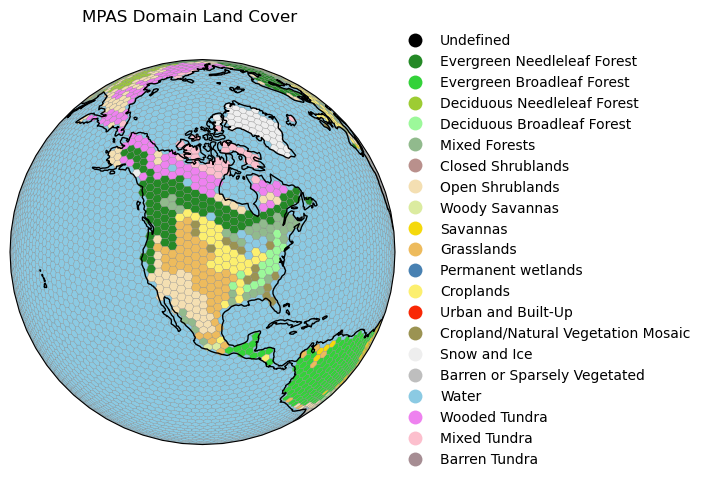

In [8]:
##################################################
#
# Projecting, Cleaning and Plotting your GeoDataFrame (Regional #1)
#

# Reproject to desired projection & remove invalid polygons

gdf_proj = gdf_land.to_crs(crs = ccrs_goes)
gdf_proj = gdf_proj[gdf_proj.is_valid]

print("Percent Loss of Polygons", 100-len(gdf_proj)/len(gdf_land)*100)

#
# Plot with Cartopy Resource Extentions
# 

fig = plt.figure(figsize=[10,5])
ax  = fig.add_subplot(1, 1, 1,                 # nrows, ncols, this index, 
                      projection = ccrs_goes)  # your projection

gdf_proj.plot(ax          = ax, 
              categorical = True,
              column      = 'Land Cover',  
              edgecolor   = "grey",
              linewidth   = 0.2,
              cmap        = ivgtyp_color_table,     
              legend      = True,
              legend_kwds={"bbox_to_anchor":[1.8, 1.1], # a lot of trial and error here.
                               "framealpha":0})         # transparent legend 

ax.add_feature(cfeature.COASTLINE)
fig.suptitle("MPAS Domain Land Cover")

plt.show()

#
##################################################

## Regional Example #2 (Lambert Conformal)

For a regional zoom in of a global field that lines up with a tradition conformal projection you can just cookie cut the main projection once you reproject and clean your GeoDataFrame.

Percent Loss of Polygons 0.9666080843585263


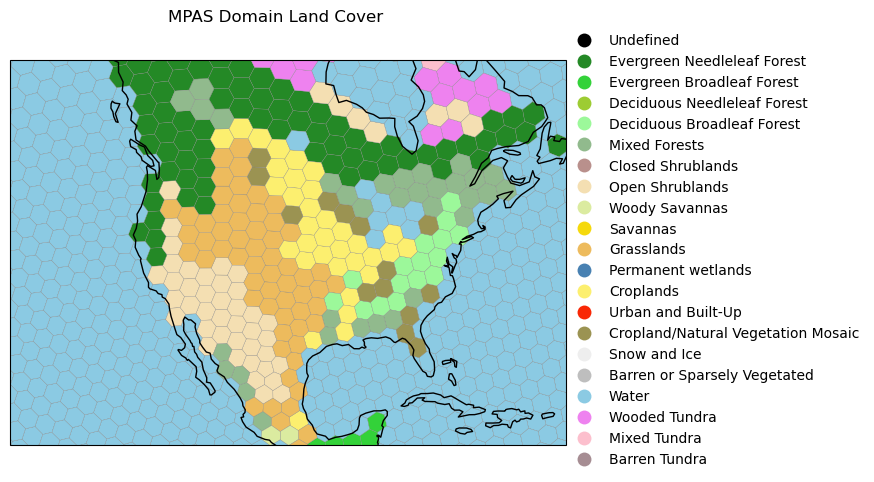

In [9]:
##################################################
#
# Projecting, Cleaning and Plotting your GeoDataFrame (Regional #2)
#

# Reproject to desired projection & remove invalid polygons

    
gdf_proj    = gdf_land.to_crs(crs = ccrs_lcc)
gdf_proj    = gdf_proj[gdf_proj.is_valid]


print("Percent Loss of Polygons", 100-len(gdf_proj)/len(gdf_land)*100)

#
# Plot with Cartopy Resource Extensions
# 

fig = plt.figure(figsize = [10,5])
ax  = fig.add_subplot(1, 1, 1,                # nrows, ncols, this index, 
                      projection = ccrs_lcc)  # your projection

gdf_proj.plot(ax          = ax, 
              categorical = True,
              column      = 'Land Cover',  
              edgecolor   = "grey",
              linewidth   = 0.2,
              cmap        = ivgtyp_color_table,     
              legend      = True,
              legend_kwds={"bbox_to_anchor":[1.55, 1.1],# a lot of trial and error here.
                               "framealpha":0}) # transparent legend 

# Apply your bounds
ax.set_xbound(lcc_minx,lcc_maxx)
ax.set_ybound(lcc_miny,lcc_maxy)

ax.add_feature(cfeature.COASTLINE)
fig.suptitle("MPAS Domain Land Cover")

plt.show()

#
##################################################

## Global Example #1 (Robinson)

Working with global data, you would think, would work fairly much the same.  

However.  

We have a problem when we reach the end of the world in our projection.  Unlike regional projections, we won't have any "invalid" points when we go beyond the projected horizon, because there is no horizon in global projections like Mercator, Plate Carrée, Robinson, etc.  

So if we use the same step...

![Don't Look!](https://kyrill.ias.sdsmt.edu/wjc/eduresources/dont_look_ok_just_once.gif)

Percent Loss of Polygons 0.19527436047647484


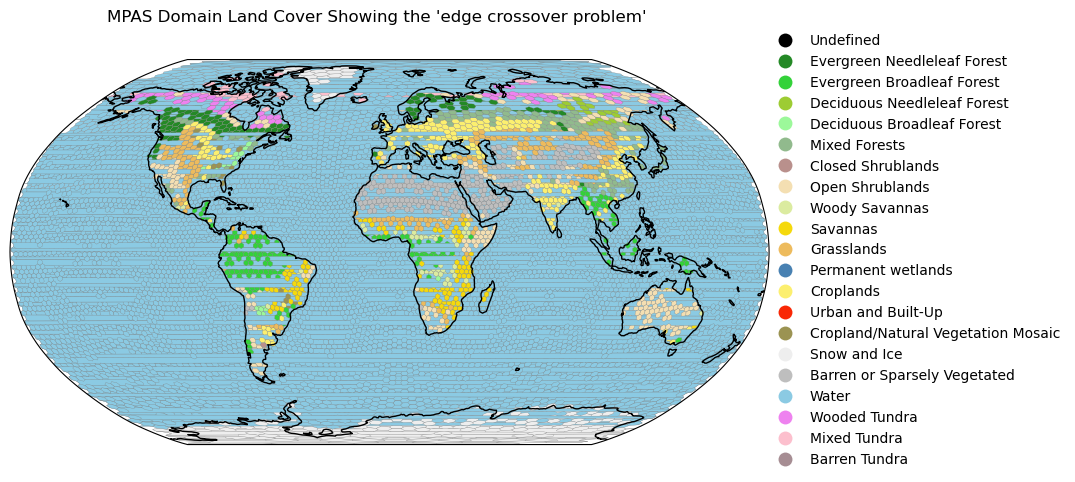

In [10]:
##################################################
#
# Projecting, Cleaning and Plotting your GeoDataFrame (Global #1)
#

# Reproject to desired projection & remove invalid polygons

gdf_proj = gdf_land.to_crs(crs = ccrs_robin)
gdf_proj = gdf_proj[gdf_proj.is_valid]

print("Percent Loss of Polygons", 100-len(gdf_proj)/len(gdf_land)*100)

#
# Plot with Cartopy Resource Extentions
# 

fig = plt.figure(figsize = [10,5])
ax  = fig.add_subplot(1, 1, 1,                # nrows, ncols, this index, 
                      projection = ccrs_robin)  # your projection

gdf_proj.plot(ax          = ax, 
              categorical = True,
              column      = 'Land Cover',  
              edgecolor   = "grey",
              linewidth   = 0.2,
              cmap        = ivgtyp_color_table,     
              legend      = True,
              legend_kwds={"bbox_to_anchor":[1.4, 1.1],# a lot of trial and error here.
                               "framealpha":0}) # transparent legend 


ax.add_feature(cfeature.COASTLINE)
fig.suptitle("MPAS Domain Land Cover Showing the 'edge crossover problem'")

plt.show()

#
##################################################

You see this not only with fancier projections but also with "Cylindrical Equidistant" / "Lat-Lon" / "Plate Carrée."

In the above scene, polygons on our edges start on one side of the word and stretch to the other.  One way to fix this is to remove the very edge polygons that cross our 180-degree east line.

The disadvantage is that at the edge of your map, you will have missing data.

I just remove those with differences in degrees longitude that are greater than a given threshold (e.g., ~300 degrees longitude, or start at 360 and work your way down until the map looks acceptable).

Percent Loss of Edge Polygons 0.9373169302870537


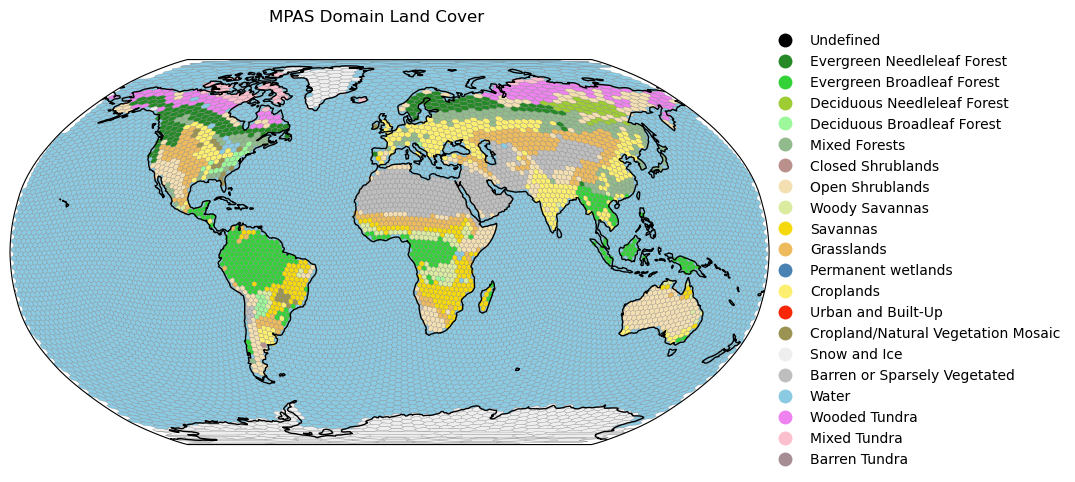

In [11]:
##################################################
#
# Projecting, Cleaning and Plotting your GeoDataFrame (Global #1)
#

# MASK and THEN... Reproject to desired projection & remove invalid polygons

valid_polys = (gdf_land.bounds["maxx"]-gdf_land.bounds["minx"]) < 355.

gdf_proj = gdf_land[valid_polys].to_crs(crs = ccrs_robin)
gdf_proj = gdf_proj[gdf_proj.is_valid]

print("Percent Loss of Edge Polygons", 100-len(gdf_proj)/len(gdf_land)*100)

#
# Plot with Cartopy Resource Extensions
# 

fig = plt.figure(figsize = [10,5])
ax  = fig.add_subplot(1, 1, 1,                # nrows, ncols, this index, 
                      projection = ccrs_robin)  # your projection

gdf_proj.plot(ax          = ax, 
              categorical = True,
              column      = 'Land Cover',  
              edgecolor   = "grey",
              linewidth   = 0.2,
              cmap        = ivgtyp_color_table,     
              legend      = True,
              legend_kwds={"bbox_to_anchor":[1.4, 1.1],# a lot of trial and error here.
                               "framealpha":0}) # transparent legend 



ax.add_feature(cfeature.COASTLINE)
fig.suptitle("MPAS Domain Land Cover")

plt.show()

#
##################################################

This method also works if you just want to do a boring "Plate Carrée" (geographic) projection.  Your gaps at the poles, however, will be much more visible.  This is likely not a best practice if you are working with continuous data.  In those cases, rendering your data as point clouds will be better suited.

Percent Loss of Edge Polygons 0.908025776215581


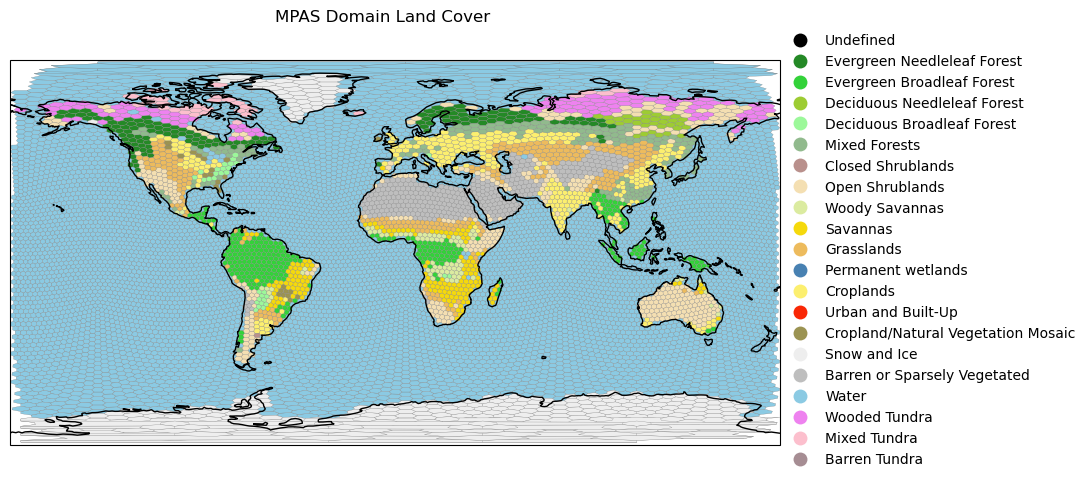

In [12]:
##################################################
#
# Projecting, Cleaning and Plotting your GeoDataFrame (Global #2)
#

# MASK and THEN... Reproject to desired projection & remove invalid polygons

valid_polys = (gdf_land.bounds["maxx"]-gdf_land.bounds["minx"]) < 355.

gdf_proj = gdf_land[valid_polys]

print("Percent Loss of Edge Polygons", 100-len(gdf_proj)/len(gdf_land)*100)

#
# Plot with Cartopy Resource Extensions
# 

fig = plt.figure(figsize = [10,5])
ax  = fig.add_subplot(1, 1, 1,                # nrows, ncols, this index, 
                      projection = ccrs.PlateCarree())  # your projection

gdf_proj.plot(ax          = ax, 
              categorical = True,
              column      = 'Land Cover',  
              edgecolor   = "grey",
              linewidth   = 0.2,
              cmap        = ivgtyp_color_table,     
              legend      = True,
              legend_kwds={"bbox_to_anchor":[1.4, 1.1],# a lot of trial and error here.
                               "framealpha":0}) # transparent legend 


ax.add_feature(cfeature.COASTLINE)
fig.suptitle("MPAS Domain Land Cover")

plt.show()

#
##################################################

## Multipanel plotting (and a refresher on how to do a universal customized colorbar)

To use the n-D plotting, the procedure from above is similar, but unfortunately, we can't use "multi-facet" style plotting that is handy in Seaborn or in R's ggplot since we are working with GeoAxes and also with Geopandas.  

For this, we will need to work with traditional multiple Axessesesses.  In this case, we are also working with GeoAxeseesssessssss.  This will also complicate making the common legend or, here, the common colorbar, since I am using this as an opportunity to work with plotting non-categorical (but still discretized at the land-surface level) data for the Fractional Vegetation Cover.  

To do the plots themselves, this is fairly easy.  You will need to set the "legend" keyword to "False" in the plotting command and [otherwise making the multi-panel plot will be no different than doing it otherwise with the basic matplotlib environment](https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html). 

For the unified colorbar, you will need to make one deviation from otherwise normal matplotlib best practices.  GeoAxes may not retain the colormap (cmap object).  Get around this, you will need to make a "standalone" set of mappable properties for the colormap using the [matplotlib.cm.ScalarMappable()](https://matplotlib.org/stable/api/cm_api.html#matplotlib.cm.ScalarMappable) class object so you can declare the same colormap as you're using in the plots above and then manually set the color ranges with the [matplotlib.colors.Normalize()](https://matplotlib.org/stable/api/_as_gen/matplotlib.colors.Normalize.html).  

To position the colorbar, the good news is that you can still use the GeoAxeses that were made to identify the space in which to do the colorbar, and it will try to automatically shift the larger common GeoAxes space and insert the colorbar by default or with your preferred settings with "location" and/or "orientation."

The process is presented below, with extensive comments when it's time to set up the colorbar.

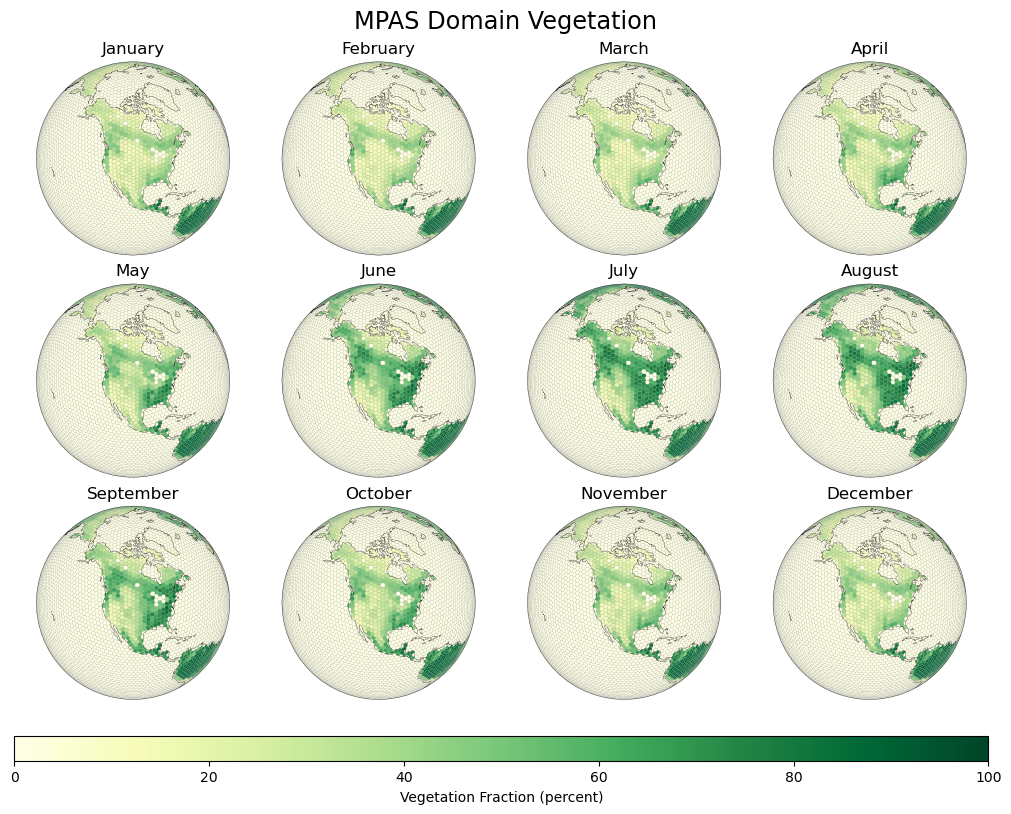

In [13]:
##################################################
#
# Projecting, Cleaning, and Plotting your GeoDataFrame (Multiindex Version)
#

# Reproject to desired projection & remove invalid polygons

gdf_proj = gdf_12month.to_crs(crs = ccrs_goes)
gdf_proj = gdf_proj[gdf_proj.is_valid]

#
# Plot with Cartopy Resource Extentions
# 
# Note the only difference here from above is that
#   I used dropped all the subplot axes up front,
#   ran the subplots through a loop.
#
# Finally below I am commenting a deep-dive on how
#   to add a "standalone" color table.


fig,ax  = plt.subplots(nrows      = 3, 
                       ncols      = 4, 
                       figsize    = [10,8],
                       subplot_kw = {"projection": ccrs_goes},
                       layout="constrained") 

fig.suptitle("MPAS Domain Vegetation", fontsize = "xx-large")


for m, month in enumerate(month_names):
    ##################################
    #
    
    r = int(m/4)      # row
    c = np.mod(m,  4) # col
    
    # print(m, r, c, month)

    sub_df = gdf_proj.loc[month] 

    sub_df.plot(ax          = ax[r,c], 
                column      = 'greenfrac',  
                edgecolor   = "grey",
                vmin        =   0,
                vmax        = 100,
                linewidth   = 0.1,
                cmap        = mpl.cm.YlGn,     
                legend      = False) 

    ax[r,c].set_title(month)
    ax[r,c].add_feature(cfeature.COASTLINE, linewidth = 0.2)
    ax[r,c].spines['geo'].set_linewidth(0.2) 

    #
    ##################################


# Tips on a global single toolbar.  
#   Since we can't do "facets"  with geopandas like you can with
#   pandas in seaborn you here we do the following:
#  
# We create a Scalar Mapping Object (we can't take an image of
#   one of our GeoAxes Graphical Objects we just made, with the 
#   methods you would do with an xarray or pandas .plot object).  
# 
# For this, we just need to identify the common color table used
#   above and also the max and min ranges.

sm = plt.cm.ScalarMappable(cmap = mpl.cm.YlGn, 
                           norm = plt.Normalize(vmin =   0, 
                                                vmax = 100)) 

# To drop the bar while we can't use the graphics object from the
#   above plotting as the "mappable" reference (hence the standalone)
#    ScalarMappable), but we DO want to "borrow" space from the multi-
#    GeoAxes space.  So the "mappable" reference points to our
#    bespoke color bar, and the ax is pointing to *all* of the 
#    GeoAxeses.
#
# Note that you may need some trial and error to get the size and aspect
#   of the bottom color bar to meet your preferred look-and-feel.

fig.colorbar(mappable    =                    sm, 
             ax          =                    ax,
             orientation =          'horizontal',
             label       = "Vegetation Fraction (percent)", 
             aspect      =                    40)

plt.show()


#
##################################################

# Version Information

*Version Information* is a package developed by J.R. Johansson and operates as what the iPython/Jupyter Environments call ["Magic Line" commands](https://jakevdp.github.io/PythonDataScienceHandbook/01.03-magic-commands.html), which are invoked by a "%."  This one is convenient since it displays detailed information on the versions of Python, Jupyter, and any other denoted packages (but for those, you DO need to delete them since this is running "outside" of your notebook program.

The output will be in JSON format in the Jupyter Lab Notebook, but it will be a professional-looking table when rendered as an HTML file.

In [14]:
################################################################
#
# Loading Version Information
#

%load_ext version_information
%version_information numpy, matplotlib, pandas, geopandas, cartopy, shapely, version_information

#
################################################################

Software,Version
Python,3.12.12 64bit [Clang 19.1.7 ]
IPython,9.13.0
OS,macOS 26.5 arm64 arm 64bit
numpy,2.4.5
matplotlib,3.10.9
pandas,3.0.3
geopandas,1.1.3
cartopy,0.25.0
shapely,2.1.2
version_information,1.0.4
